# Haishoku starter: Sanzo Wada's 348 color combinations
This notebook loads the three tidy tables, joins them, and looks at hue distribution, combination sizes, the most-used colors, the strongest color pairs, and lightness contrast within each palette.

Data: CC BY 4.0. Please credit Sanzo Wada (*Haishoku Sōkan*, 1933–34), Seigensha (*A Dictionary of Color Combinations*, 2010), and Bill Mageni's [haishoku](https://github.com/Bjoseph23/haishoku).

In [1]:
import glob, os, itertools
import pandas as pd
import matplotlib.pyplot as plt

# find the data folder on Kaggle or locally
cands = glob.glob('/kaggle/input/**/colors.csv', recursive=True) + ['colors.csv']
DATA = os.path.dirname([c for c in cands if os.path.exists(c)][0]) or '.'
colors = pd.read_csv(f'{DATA}/colors.csv')
combos = pd.read_csv(f'{DATA}/combinations.csv')
slots  = pd.read_csv(f'{DATA}/combination_colors.csv')
print(colors.shape, combos.shape, slots.shape)
colors.head()

(159, 33) (348, 9) (1032, 9)


,id,name,base,c,m,y,k,hex_cmyk,scan_hex,display_hex,...,hsl_l,hue_family,is_variant,ref_page,combo_count,combo_count_2,combo_count_3,combo_count_4,appears_in,note
0,1,Hermosa Pink,Hermosa Pink,0,30,6,0,#FFB2F0,#CEACC2,#FACDDE,...,89.2,pink,False,285,3,0,2,1,176 227 273,NaN
1,2,Corinthian Pink,Corinthian Pink,0,35,15,0,#FFA6D9,#CCA2B0,#F8C1C9,...,86.5,pink,False,285,12,4,4,4,027 043 087 097 128 169 174 206 246 254 264 342,NaN
2,3,Cameo Pink,Cameo Pink,10,32,19,0,#E6ADCF,#BC9FAE,#E4BDC7,...,81.8,pink,False,285,6,4,2,0,101 105 116 120 165 231,NaN
3,4,Fawn,Fawn,18,31,30,0,#D1B0B2,#AA9697,#CEB3AD,...,74.3,pink,False,285,3,1,1,1,018 125 308,NaN
4,5,Light Brown Drab,Light Brown Drab,8,30,20,25,#B08699,#987C87,#B9949A,...,65.3,red,False,287,10,2,4,4,035 068 185 191 223 239 244 268 285 321,NaN


## Integrity checks

In [2]:
assert colors.id.is_unique and len(colors) == 159
assert combos.number.is_unique and len(combos) == 348
assert len(slots) == 1032 and not slots.duplicated(['combination_number','slot']).any()
assert slots.color_id.isin(colors.id).all() and slots.combination_number.isin(combos.number).all()
assert (slots.groupby('combination_number').size() == combos.set_index('number')['size']).all()
print('all checks passed')

all checks passed


## Join into one tidy table

In [3]:
tidy = (slots.merge(colors[['id','hue_family','lab_l','lab_a','lab_b','hsl_h','hsl_s']], left_on='color_id', right_on='id')
             .merge(combos[['number','size','page']], left_on='combination_number', right_on='number')
             .drop(columns=['id','number']))
tidy.head()

,combination_number,slot,position,color_id,color_name,display_hex,page_sample_hex,label_ocr_match,delta_e,hue_family,lab_l,lab_a,lab_b,hsl_h,hsl_s,size,page
0,1,1,left,66,English Red,#E45B1E,#CF3B0B,1.00,4.5,orange,56.16,50.63,58.04,18.5,78.6,2,28
1,1,2,right,118,Cerulian Blue,#1C93B2,#0C75A4,1.00,5.1,cyan,56.41,-20.05,-25.01,192.4,72.8,2,28
2,2,1,left,130,Dark Tyrian Blue,#2C2C47,#172044,1.00,4.7,blue,19.19,7.67,-16.83,240.0,23.5,2,28
3,2,2,right,62,Yellow Orange,#FF9B17,#F07A06,0.92,6.2,orange,72.74,29.35,74.22,34.1,100.0,2,28
4,3,1,left,40,Pale Lemon Yellow,#FFF2BF,#CCC398,1.00,3.2,yellow,95.38,-3.34,26.24,47.8,100.0,2,29


## Combination sizes

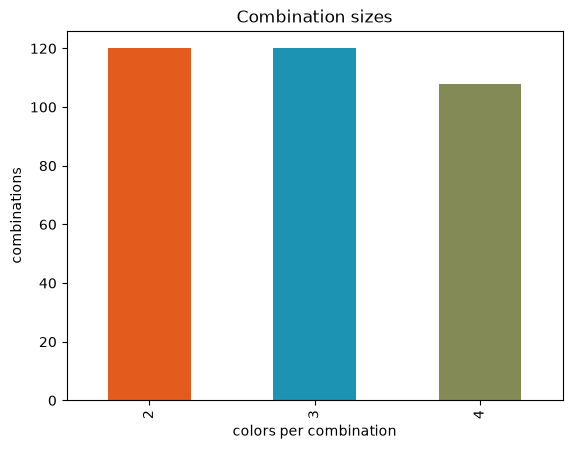

In [4]:
ax = combos['size'].value_counts().sort_index().plot.bar(color=['#E45B1E','#1C93B2','#848A55'])
ax.set(xlabel='colors per combination', ylabel='combinations', title='Combination sizes'); plt.show()

## Hue distribution of the 159 colors
Each bar is one color, placed by HSL hue and painted in its own `display_hex`.

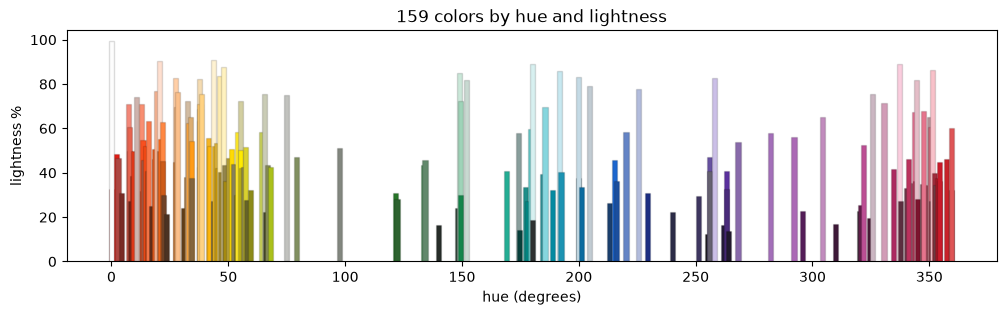

hue_family
red        26
orange     24
yellow     19
brown      15
green      14
blue       12
cyan       11
magenta     9
gray        9
violet      8
olive       6
pink        5
white       1
Name: count, dtype: int64

In [5]:
fig, ax = plt.subplots(figsize=(12, 3))
c = colors.sort_values('hsl_h')
ax.bar(c.hsl_h, c.hsl_l, width=2.2, color=c.display_hex, edgecolor='#00000022')
ax.set(xlabel='hue (degrees)', ylabel='lightness %', title='159 colors by hue and lightness'); plt.show()
colors.hue_family.value_counts()

## The 20 most-used colors

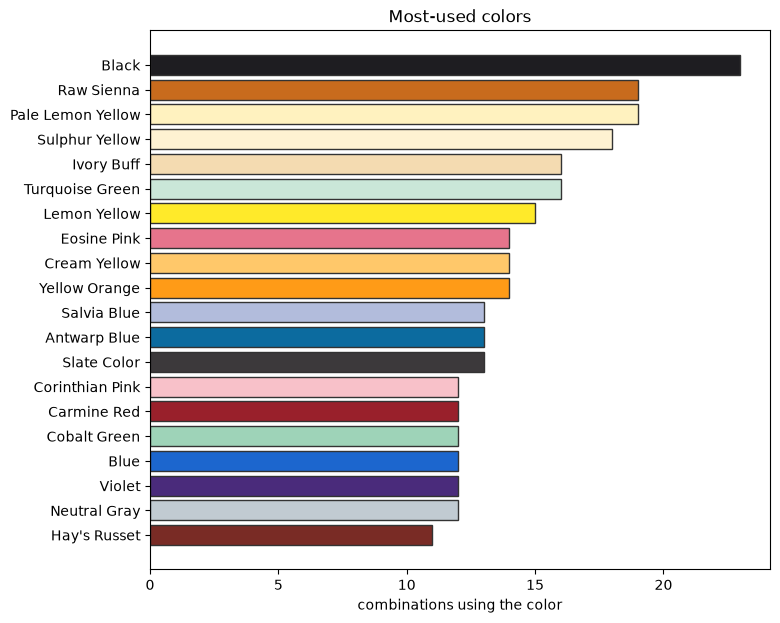

In [6]:
top = colors.nlargest(20, 'combo_count')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.name[::-1], top.combo_count[::-1], color=top.display_hex[::-1], edgecolor='#333')
ax.set(xlabel='combinations using the color', title='Most-used colors'); plt.show()

## Strongest color pairs (co-occurrence)

In [7]:
pairs = (slots.groupby('combination_number').color_id.apply(lambda s: list(itertools.combinations(sorted(s), 2)))
         .explode().value_counts().head(15).rename('count').reset_index())
name = colors.set_index('id').name
pairs[['a','b']] = pd.DataFrame(pairs.iloc[:,0].tolist(), index=pairs.index)
pairs.assign(a=pairs.a.map(name), b=pairs.b.map(name))[['a','b','count']]

,a,b,count
0,Orange,Black,3
1,Pale Lemon Yellow,Warm Gray,3
2,Cream Yellow,Benzol Green,3
3,Sulphur Yellow,Cossack Green,3
4,Sulphur Yellow,Salvia Blue,3
5,Cream Yellow,Blue,3
6,Raw Sienna,Black,3
7,Cinnamon Buff,Light Mauve,2
8,Red Orange,Pale Lemon Yellow,2
9,Raw Sienna,Slate Color,2


## Lightness contrast within palettes
The ΔL\* range (max minus min CIELAB lightness) in each combination, by size.

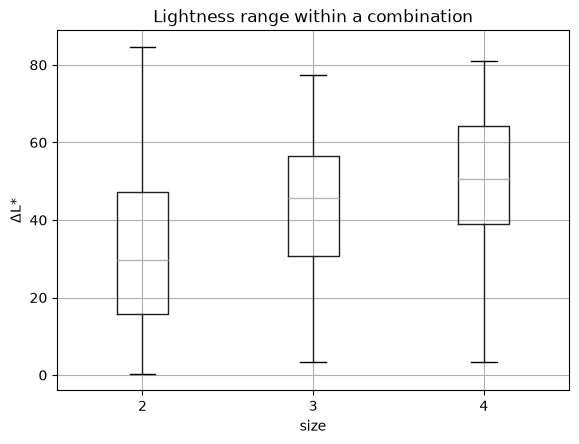

,count,mean,std,min,25%,50%,75%,max
size,,,,,,,,
2,120.0,32.328583,20.988565,0.25,15.7525,29.655,47.2125,84.65
3,120.0,43.176000,16.738984,3.46,30.6300,45.635,56.5600,77.45
4,108.0,50.699815,17.710723,3.30,38.9700,50.495,64.2350,80.96


In [8]:
rng = tidy.groupby(['combination_number','size']).lab_l.agg(lambda s: s.max()-s.min()).rename('delta_L').reset_index()
rng.boxplot(column='delta_L', by='size'); plt.suptitle(''); plt.title('Lightness range within a combination'); plt.ylabel('ΔL*'); plt.show()
rng.groupby('size').delta_L.describe()

## Draw any combination

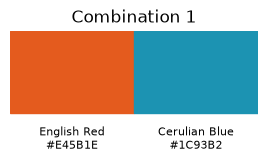

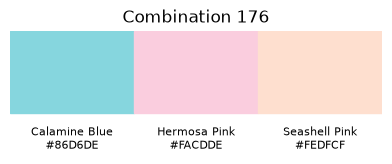

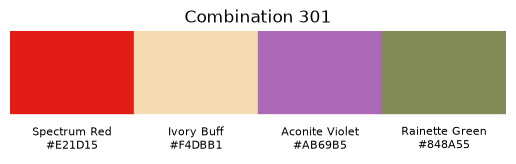

In [9]:
def show(n):
    s = slots[slots.combination_number == n]
    fig, ax = plt.subplots(figsize=(len(s)*1.6, 1.6))
    for i, r in enumerate(s.itertuples()):
        ax.add_patch(plt.Rectangle((i,0),1,1,color=r.display_hex)); ax.text(i+.5,-.15,f'{r.color_name}\n{r.display_hex}',ha='center',va='top',fontsize=8)
    ax.set_xlim(0,len(s)); ax.set_ylim(-.5,1); ax.axis('off'); ax.set_title(f'Combination {n}'); plt.show()
for n in (1, 176, 301): show(n)